# **Problem Statement**

## Context

Car crashes are a leading cause of injury and death worldwide, and improving vehicle safety is a critical concern for car manufacturers. With advancements in technology and engineering, manufacturers are continuously seeking ways to design safer vehicles to reduce fatalities and severe injuries in the event of a crash. Despite these efforts, understanding the precise factors that contribute to survival in car crashes remains a complex challenge.

The problem arises from the nature of car accidents, where various elements such as impact speed, the use of safety features, the type of collision, and the demographics of the occupants all play significant roles. Each crash is unique, and even minor variations can significantly affect the outcome for the occupants. This complexity necessitates a detailed analysis to identify which factors are most influential in determining survival outcomes.

Solving this problem is essential for several reasons:

1. Safety Regulations
2. Design Improvements
3. Public Health
4. Consumer Confidence

## Objective


Over the last year, the Department of Road Transport has witnessed a 15% YoY rise in the number of car crashes happening in urban areas. While they have the causes of the accidents post-facto, they want to preempt the risk to increase road safety.

You have been hired as a data scientist and provided with a sample of the historical car crashes over 5 years, with different attributes of the car and the occupant relevant to the car crash. Your objective is to analyze the data, identify patterns in car crashes, build a predictive model to determine the likelihood of survival in car crashes based on the factors and identify the most critical factors that influence survival outcomes, thereby helping the department come up with necessary safety regulations that must be adopted by all vehicle manufacturers and users.

## Data Description

The data contains the different attributes of car crashes, with the outcome variable being whether the occupant was deceased during the crash or not. The detailed data dictionary is given below.

**Data Dictionary**

* caseid: character, created by pasting together the population sampling unit, the case number, and the vehicle number. Within each year, use this to uniquely identify the vehicle.
* speed_range: factor with levels (estimated impact speeds) 1-9 km/h, 10-24 km/h, 25-39 km/h, 40-54 km/h, 55+ km/h
*  weight: Observation weights, albeit of uncertain accuracy, are designed to account for varying sampling probabilities. (The inverse probability weighting estimator can be used to demonstrate causality when the researcher cannot conduct a controlled experiment but has observed data to model)
* seatbelt: a factor with levels none or belted
* frontal_impact: a numeric vector; 0 = non-frontal, 1=frontal impact
* sex: a factor with levels f: Female or m: Male
* age_of_occ: age of occupant in years
* year_of_acc: year of accident
* model_year: Year of model of vehicle; a numeric vector
* airbag: Did one or more (driver or passenger) airbag(s) deploy? This factor has levels deploy, nodeploy, and unavail
* occ_role: a factor with levels driver or pass: passenger
* deceased: the target variable with levels no (survived) or yes (not survived / deceased)


# **Please read the instructions carefully before starting the project.**

This is a commented Python Notebook file in which all the instructions and tasks to be performed are mentioned.
* Blanks '_______' are provided in the notebook that
needs to be filled with an appropriate code to get the correct result. With every '_______' blank, there is a comment that briefly describes what needs to be filled in the blank space.
* Identify the task to be performed correctly, and only then proceed to write the required code.
* Fill the code wherever asked by the commented lines like "# write your code here" or "# complete the code". Running incomplete code may throw error.
* Please run the codes in a sequential manner from the beginning to avoid any unnecessary errors.
* Add the results/observations (wherever mentioned) derived from the analysis in the presentation and submit the same.

# **Importing the necessary libraries**

In [ ]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)
# setting the precision of floating numbers to 5 decimal points
pd.set_option("display.float_format", lambda x: "%.5f" % x)

# Library to split data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# To build model for prediction
import statsmodels.api as SM
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# To tune different models
from sklearn.model_selection import GridSearchCV

# To get diferent metric scores
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix,
    roc_auc_score,
    precision_recall_curve,
    roc_curve
)

import warnings
warnings.filterwarnings("ignore")

# **Loading the dataset**

In [ ]:
# uncomment and run the following lines for Google Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
cars = pd.read_csv('/content/drive/MyDrive/CSV/Car_Crash.csv')    ##  complete the code to read the data

In [ ]:
# copying data to another variable to avoid any changes to original data
data = cars.copy()

# **Data Overview**

### View the first and last 5 rows of the dataset

In [ ]:
data.head(5) ##  Complete the code to view top 5 rows of the data

,caseid,speed_range,weight,seatbelt,frontal_impact,sex,age_of_occ,year_of_acc,model_year,airbag,occ_role,deceased
0,02:13:02,55+ km/h,27.07800,none,1,m,32,1997,1987,unavail,driver,yes
1,02:17:01,25-39 km/h,89.62700,belted,0,f,54,1997,1994,nodeploy,driver,yes
2,0.138206019,55+ km/h,27.07800,belted,1,m,67,1997,1992,unavail,driver,yes
3,0.138206019,55+ km/h,27.07800,belted,1,f,64,1997,1992,unavail,pass,yes
4,04:58:01,55+ km/h,13.37400,none,1,m,23,1997,1986,unavail,driver,yes


In [ ]:
data.tail(5) ##  Complete the code to view last 5 rows of the data

,caseid,speed_range,weight,seatbelt,frontal_impact,sex,age_of_occ,year_of_acc,model_year,airbag,occ_role,deceased
11212,82:107:1,25-39 km/h,3179.68800,belted,1,m,17,2002,1985,unavail,driver,no
11213,82:108:2,10-24 km/h,71.22800,belted,1,m,54,2002,2002,nodeploy,driver,no
11214,82:110:1,10-24 km/h,10.47400,belted,1,f,27,2002,1990,deploy,driver,no
11215,82:110:2,25-39 km/h,10.47400,belted,1,f,18,2002,1999,deploy,driver,no
11216,82:110:2,25-39 km/h,10.47400,belted,1,m,17,2002,1999,deploy,pass,no


### Understand the shape of the dataset

In [ ]:
data.shape ##  Complete the code to view dimensions of the data

(11217, 12)

### Check the data types of the columns for the dataset

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11217 entries, 0 to 11216
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   caseid          11217 non-null  object 
 1   speed_range     11217 non-null  object 
 2   weight          11217 non-null  float64
 3   seatbelt        11217 non-null  object 
 4   frontal_impact  11217 non-null  int64  
 5   sex             11217 non-null  object 
 6   age_of_occ      11217 non-null  int64  
 7   year_of_acc     11217 non-null  int64  
 8   model_year      11217 non-null  int64  
 9   airbag          11217 non-null  object 
 10  occ_role        11217 non-null  object 
 11  deceased        11217 non-null  object 
dtypes: float64(1), int64(4), object(7)
memory usage: 1.0+ MB


### Statistical summary of the dataset

In [ ]:
data.describe(include='all').T ##  Complete the code to view the statistical summary of the data

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
caseid,11217,6099,0.604872685,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
speed_range,11217,5,10-24 km/h,5414,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,11217.00000,NaN,NaN,NaN,431.40531,1406.20294,0.00000,28.29200,82.19500,324.05600,31694.04000
seatbelt,11217,2,belted,7849,NaN,NaN,NaN,NaN,NaN,NaN,NaN
frontal_impact,11217.00000,NaN,NaN,NaN,0.64402,0.47883,0.00000,0.00000,1.00000,1.00000,1.00000
sex,11217,2,m,6048,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_of_occ,11217.00000,NaN,NaN,NaN,37.42765,18.19243,16.00000,22.00000,33.00000,48.00000,97.00000
year_of_acc,11217.00000,NaN,NaN,NaN,2001.10324,1.05681,1997.00000,2001.00000,2001.00000,2002.00000,2002.00000
model_year,11217.00000,NaN,NaN,NaN,1994.17794,5.65870,1953.00000,1991.00000,1995.00000,1999.00000,2003.00000
airbag,11217,3,deploy,4365,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Checking for duplicate values

In [ ]:
# checking for duplicate values
data.duplicated().sum()


np.int64(0)

### Checking for missing values

In [ ]:
data.isnull().sum()
 ##  Complete the code to view the missing values in the dataset

,0
caseid,0
speed_range,0
weight,0
seatbelt,0
frontal_impact,0
sex,0
age_of_occ,0
year_of_acc,0
model_year,0
airbag,0


### Creating the veh_usage_duration variable

* veh_usage_duration: Indicates the time period (in years) the vehicle has been in use

In [ ]:
data['veh_usage_duration'] = data['year_of_acc'] - data['model_year']

# **Exploratory Data Analysis (EDA)**

### Functions for EDA

**The below functions need to be defined to carry out the EDA.**

In [ ]:
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [ ]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 2, 6))
    else:
        plt.figure(figsize=(n + 2, 6))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        hue=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n],
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

In [ ]:
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

In [ ]:
### function to plot distributions wrt target


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
        stat="density",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
        stat="density",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

### Univariate Analysis

#### Observations on deceased

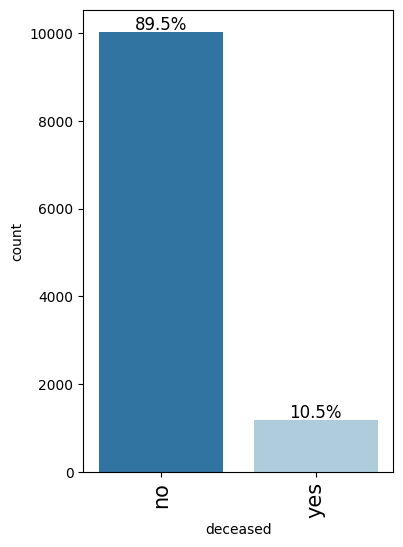

In [ ]:
labeled_barplot(data, "deceased", perc=True)  ##Complete the code to get the labeled_barplot for deceased

#### Observations on weight

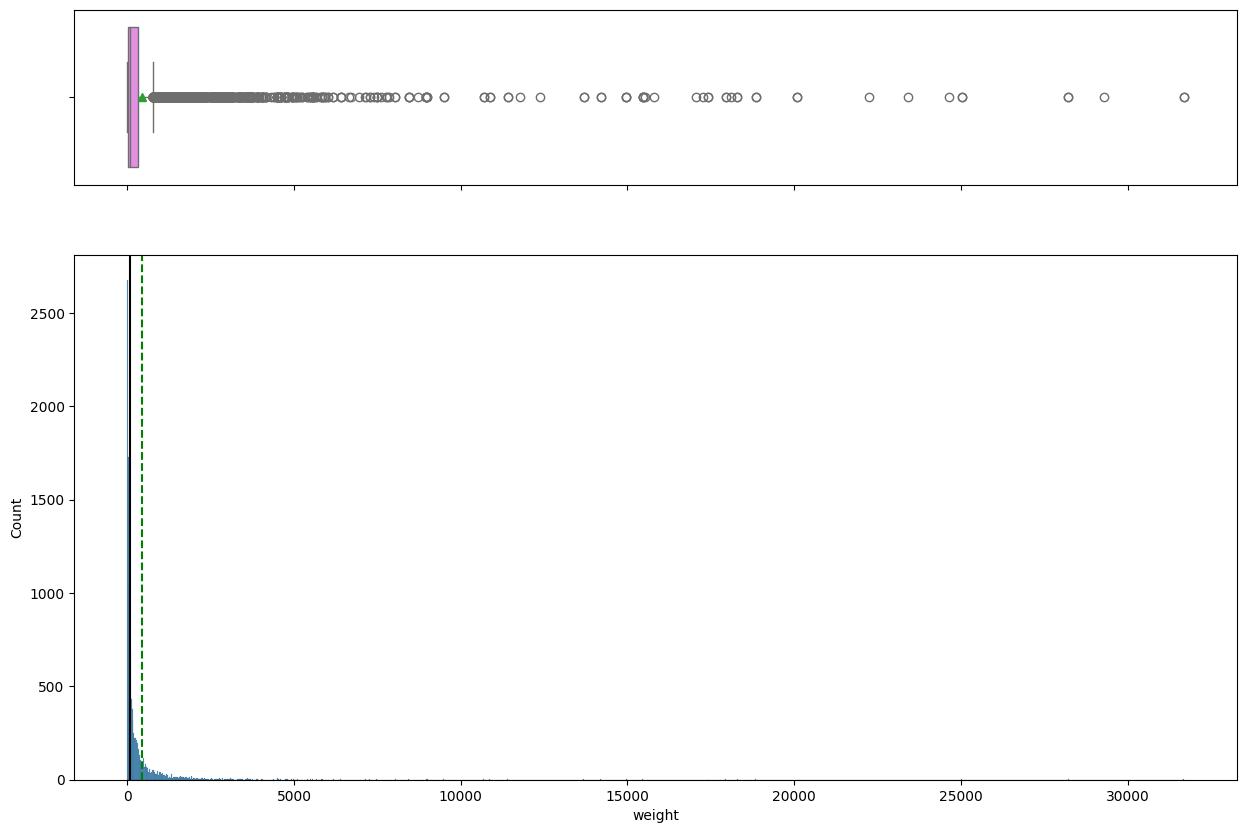

In [ ]:
histogram_boxplot(data, "weight")

#### Observations on age_of_occ

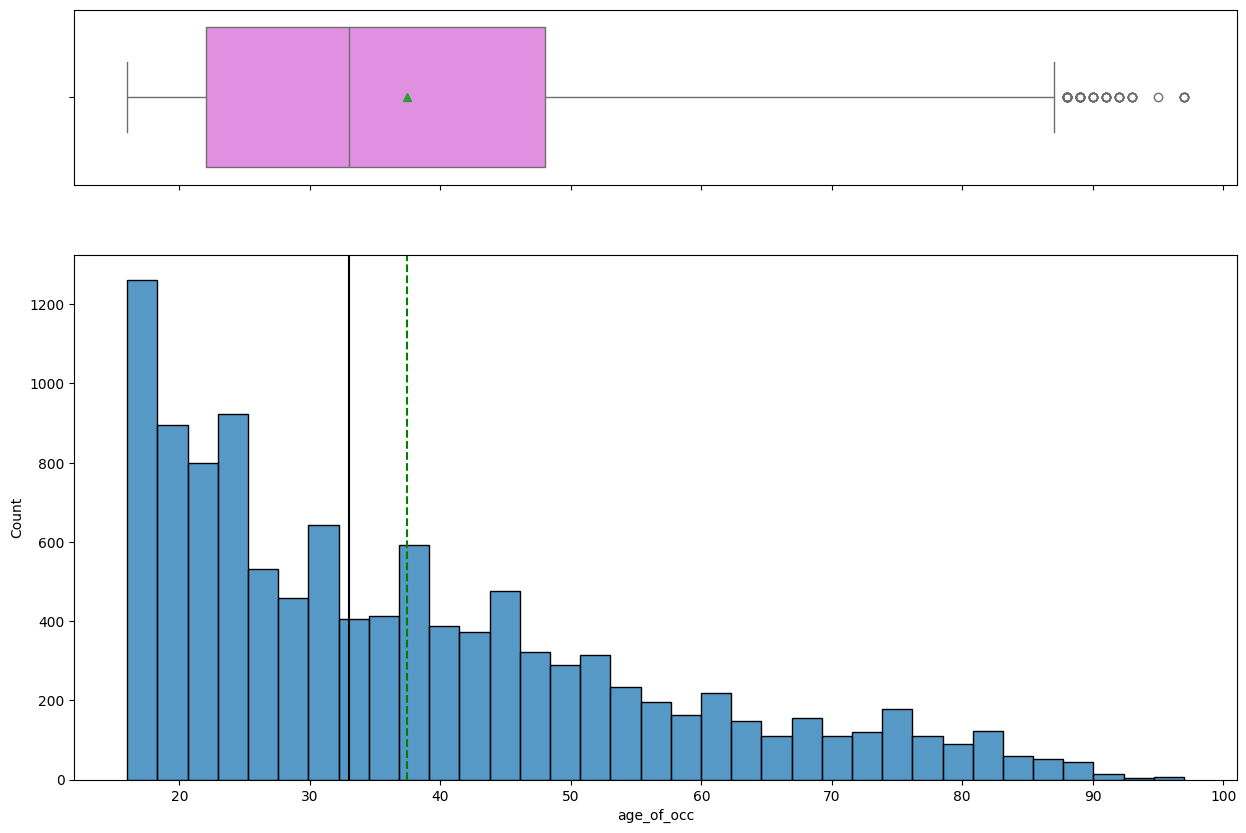

In [ ]:
histogram_boxplot(data, "age_of_occ")  ##Complete the code to get the histogram_boxplot for age_of_occ

#### Observations on speed_range

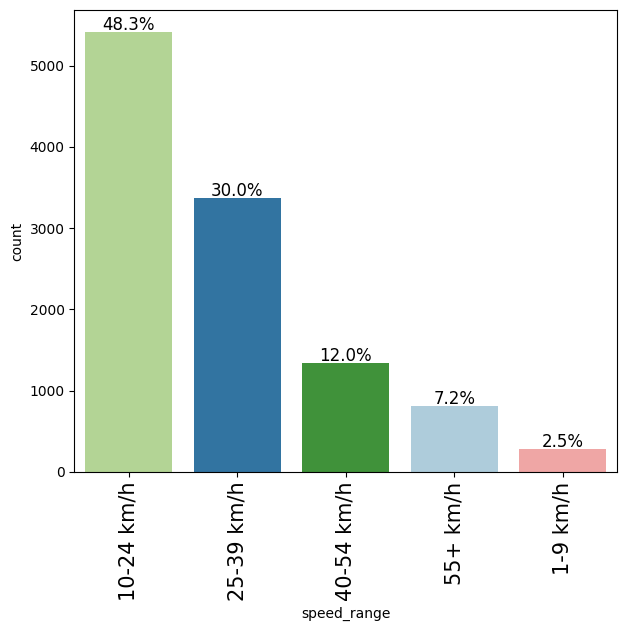

In [ ]:
labeled_barplot(data, "speed_range", perc=True)  ##Complete the code to get the labeled_barplot for speed_range

#### Observations on airbag

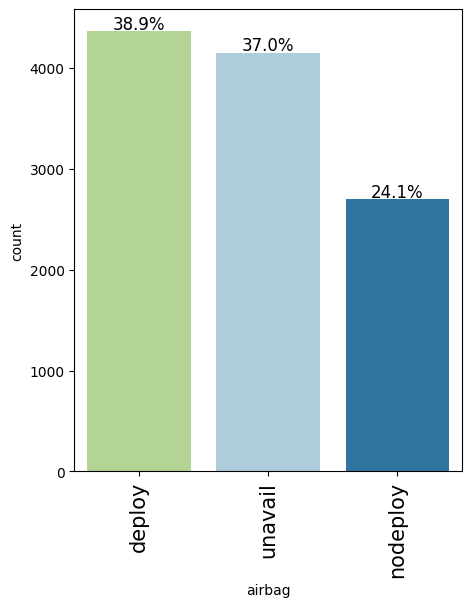

In [ ]:
labeled_barplot(data, "airbag", perc=True)  ##Complete the code to get the labeled_barplot for airbag

#### Observations on seatbelt

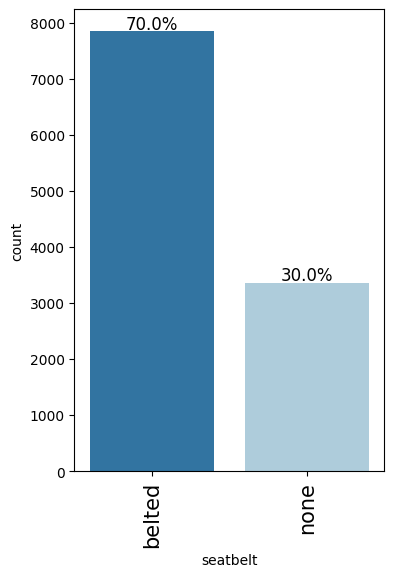

In [ ]:
labeled_barplot(data, "seatbelt", perc=True)  ##Complete the code to get the labeled_barplot for seatbelt

#### Observations on frontal_impact

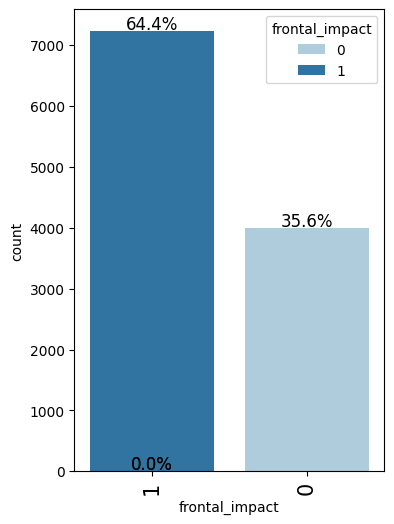

In [ ]:
labeled_barplot(data, "frontal_impact", perc=True)  ##Complete the code to get the labeled_barplot for frontal_impact

#### Observations on sex

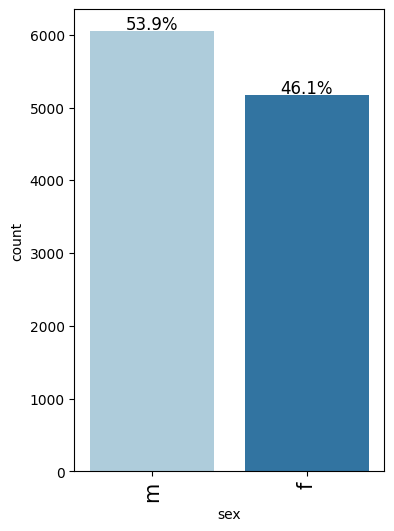

In [ ]:
labeled_barplot(data, "sex", perc=True)  ##Complete the code to get the labeled_barplot for sex

#### Observations on model_year

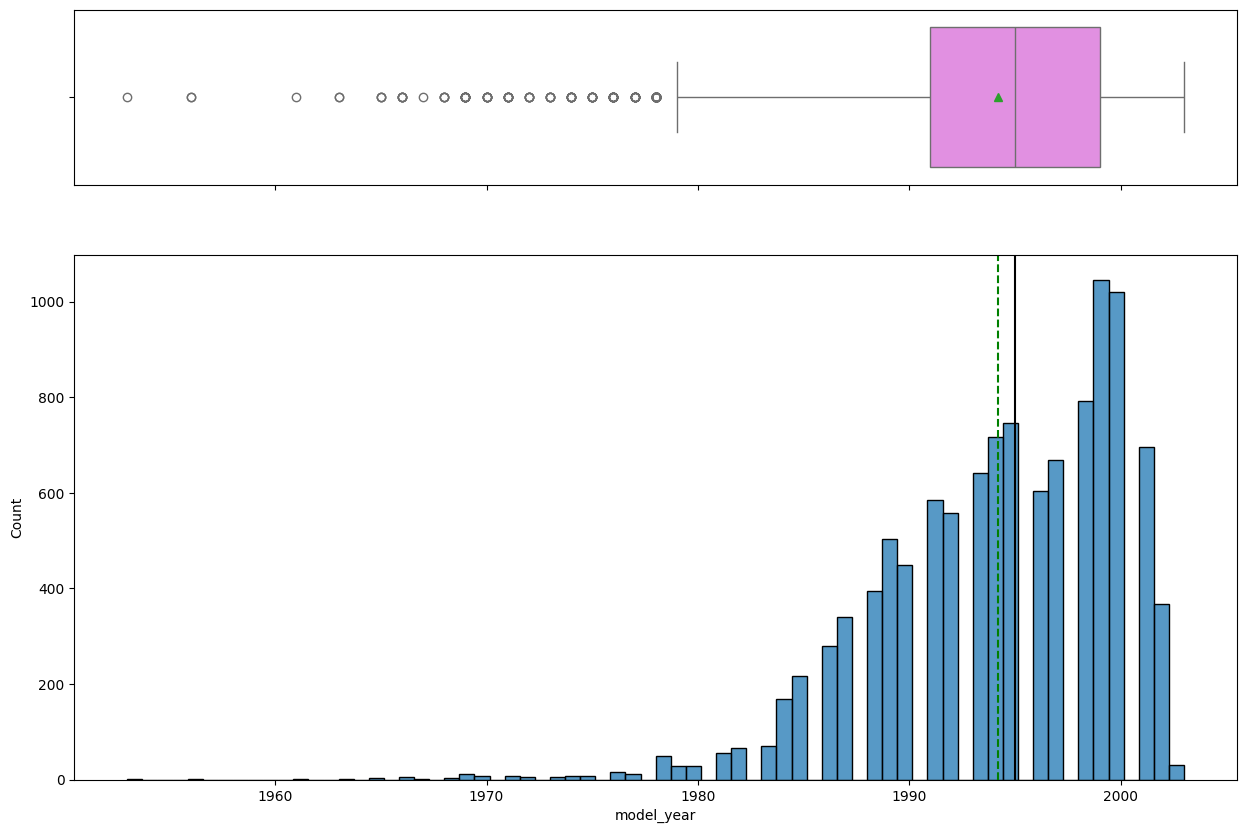

In [ ]:
histogram_boxplot(data, "model_year")  ##Complete the code to get the histogram_boxplot for model_year

#### Observations on occ_role

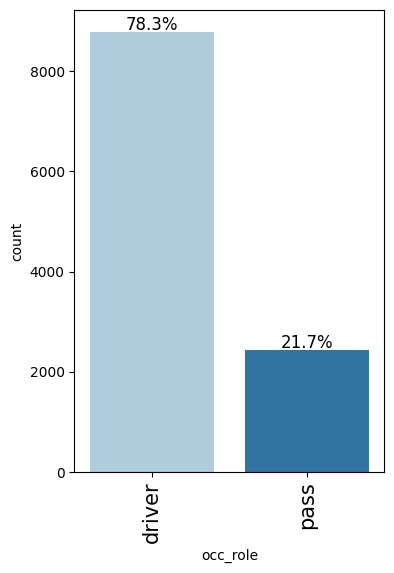

In [ ]:
labeled_barplot(data, "occ_role", perc=True)  ##Complete the code to get the labeled_barplot for occ_role

####  Observations on veh_usage_duration

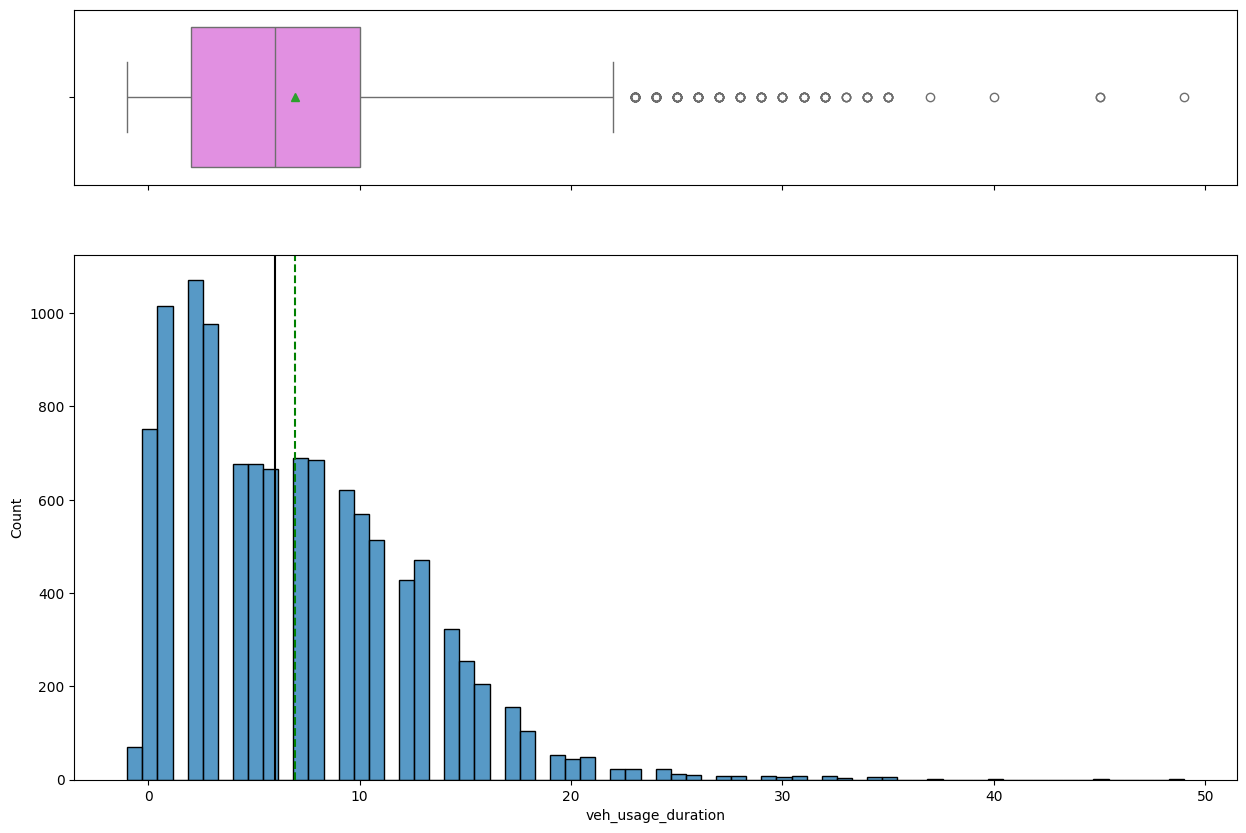

In [ ]:
histogram_boxplot(data, "veh_usage_duration")  ##Complete the code to get the histogram_boxplot for veh_usage_duration

### Bivariate Analysis

deceased        no   yes    All
speed_range                    
All          10037  1180  11217
55+ km/h       394   415    809
40-54 km/h    1000   344   1344
25-39 km/h    3064   304   3368
10-24 km/h    5300   114   5414
1-9 km/h       279     3    282
------------------------------------------------------------------------------------------------------------------------


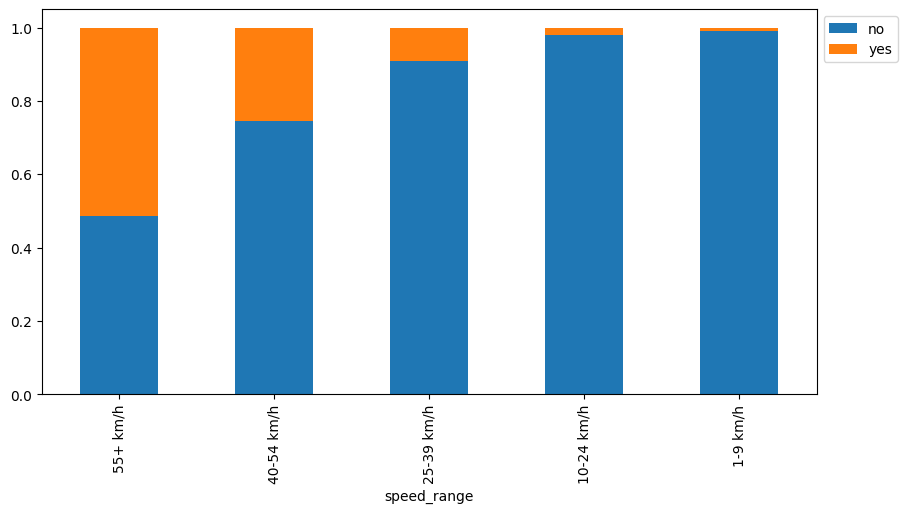

In [ ]:
stacked_barplot(data, "speed_range", "deceased")

deceased     no   yes    All
seatbelt                    
All       10037  1180  11217
none       2688   680   3368
belted     7349   500   7849
------------------------------------------------------------------------------------------------------------------------


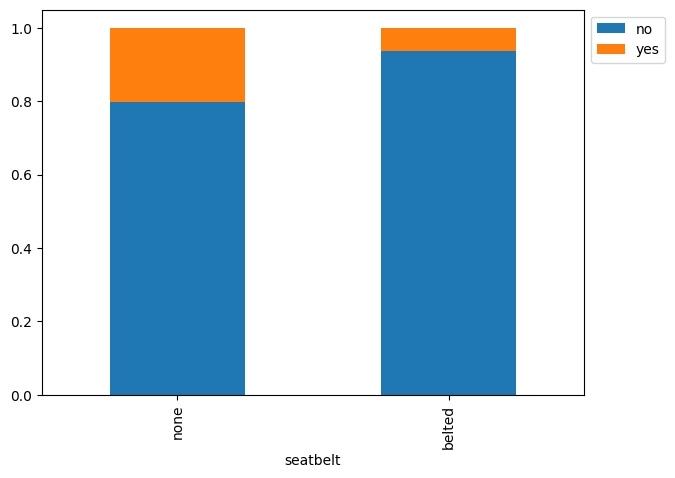

In [ ]:
stacked_barplot(data, "seatbelt", "deceased") ## Complete the code to get stacked_barplot for seatbelt and deceased

deceased           no   yes    All
frontal_impact                    
All             10037  1180  11217
0                3395   598   3993
1                6642   582   7224
------------------------------------------------------------------------------------------------------------------------


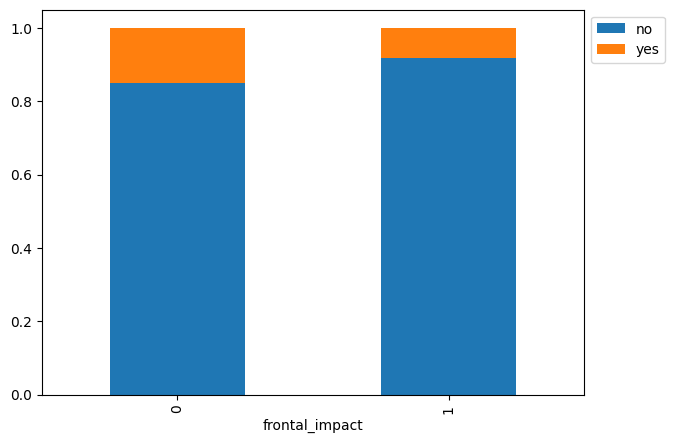

In [ ]:
stacked_barplot(data, "frontal_impact", "deceased")  ## Complete the code to get stacked_barplot for frontal_impact and deceased

deceased     no   yes    All
sex                         
All       10037  1180  11217
m          5332   716   6048
f          4705   464   5169
------------------------------------------------------------------------------------------------------------------------


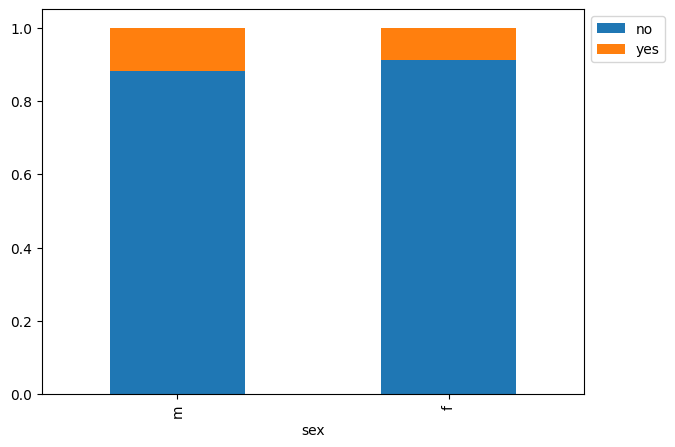

In [ ]:
stacked_barplot(data, "sex", "deceased")  ## Complete the code to get stacked_barplot for sex and deceased

deceased     no   yes    All
airbag                      
All       10037  1180  11217
unavail    3484   669   4153
deploy     3997   368   4365
nodeploy   2556   143   2699
------------------------------------------------------------------------------------------------------------------------


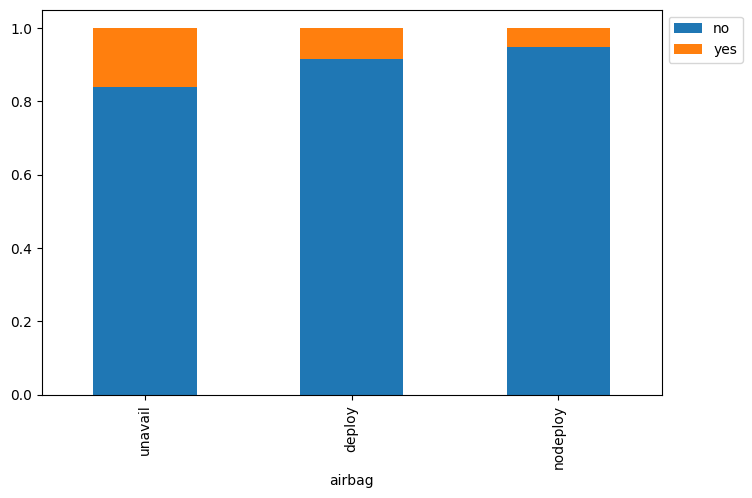

In [ ]:
stacked_barplot(data, "airbag", "deceased")  ## Complete the code to get stacked_barplot for airbag and deceased

deceased     no   yes    All
occ_role                    
All       10037  1180  11217
driver     7895   891   8786
pass       2142   289   2431
------------------------------------------------------------------------------------------------------------------------


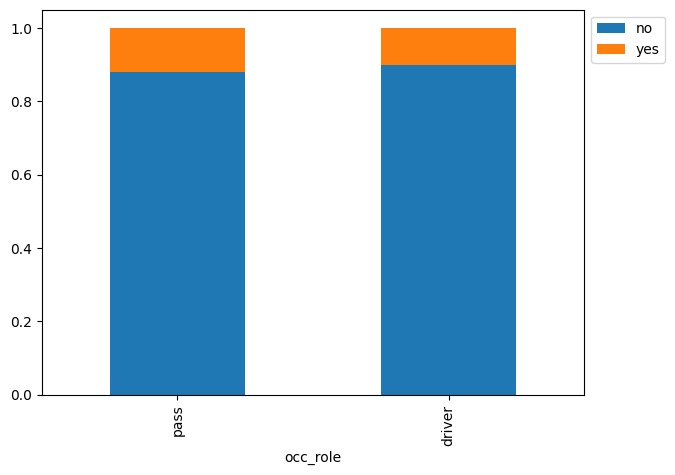

In [ ]:
stacked_barplot(data, "occ_role", "deceased")  ## Complete the code to get stacked_barplot for occ_role and deceased

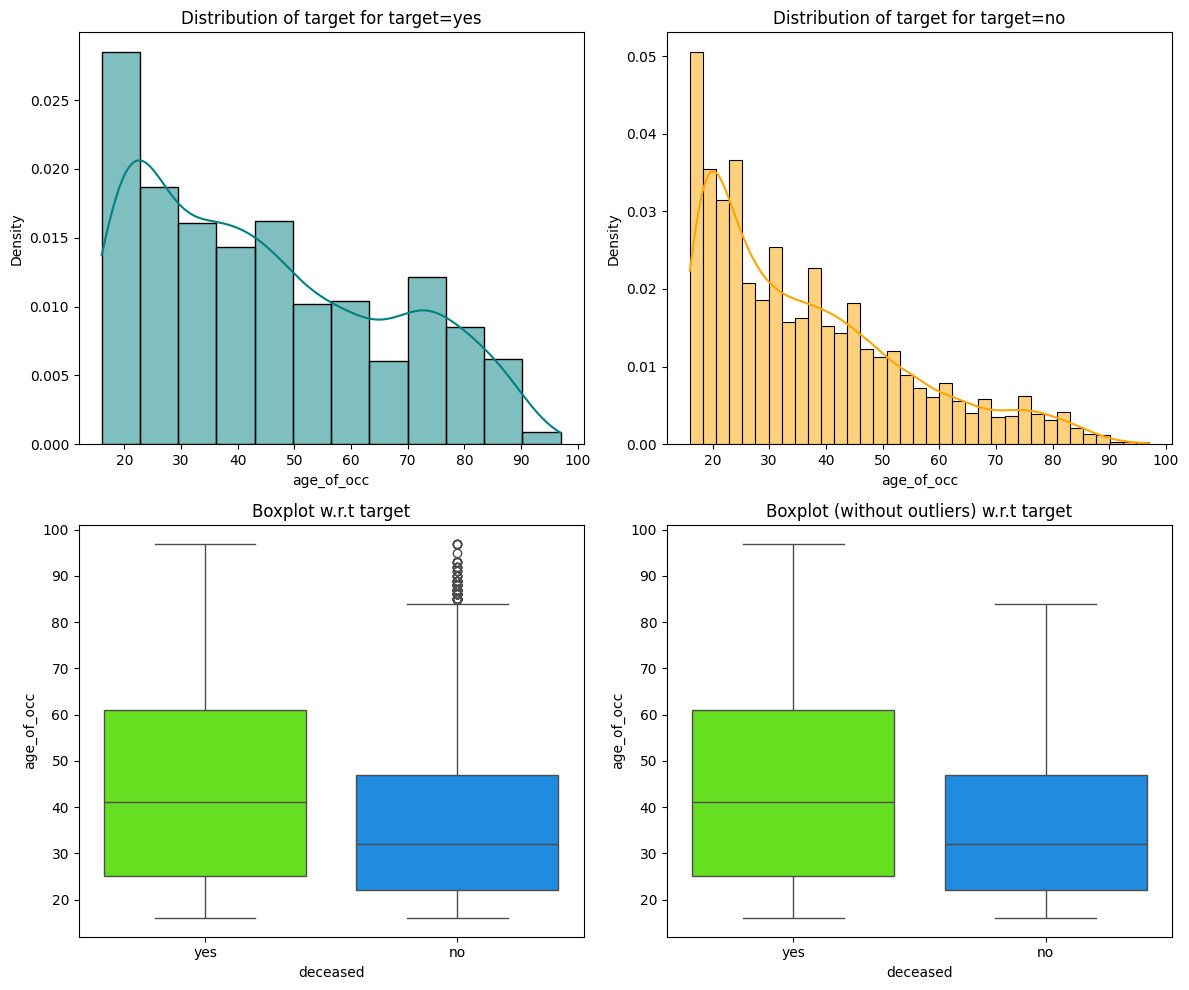

In [ ]:
distribution_plot_wrt_target(data, "age_of_occ", "deceased")

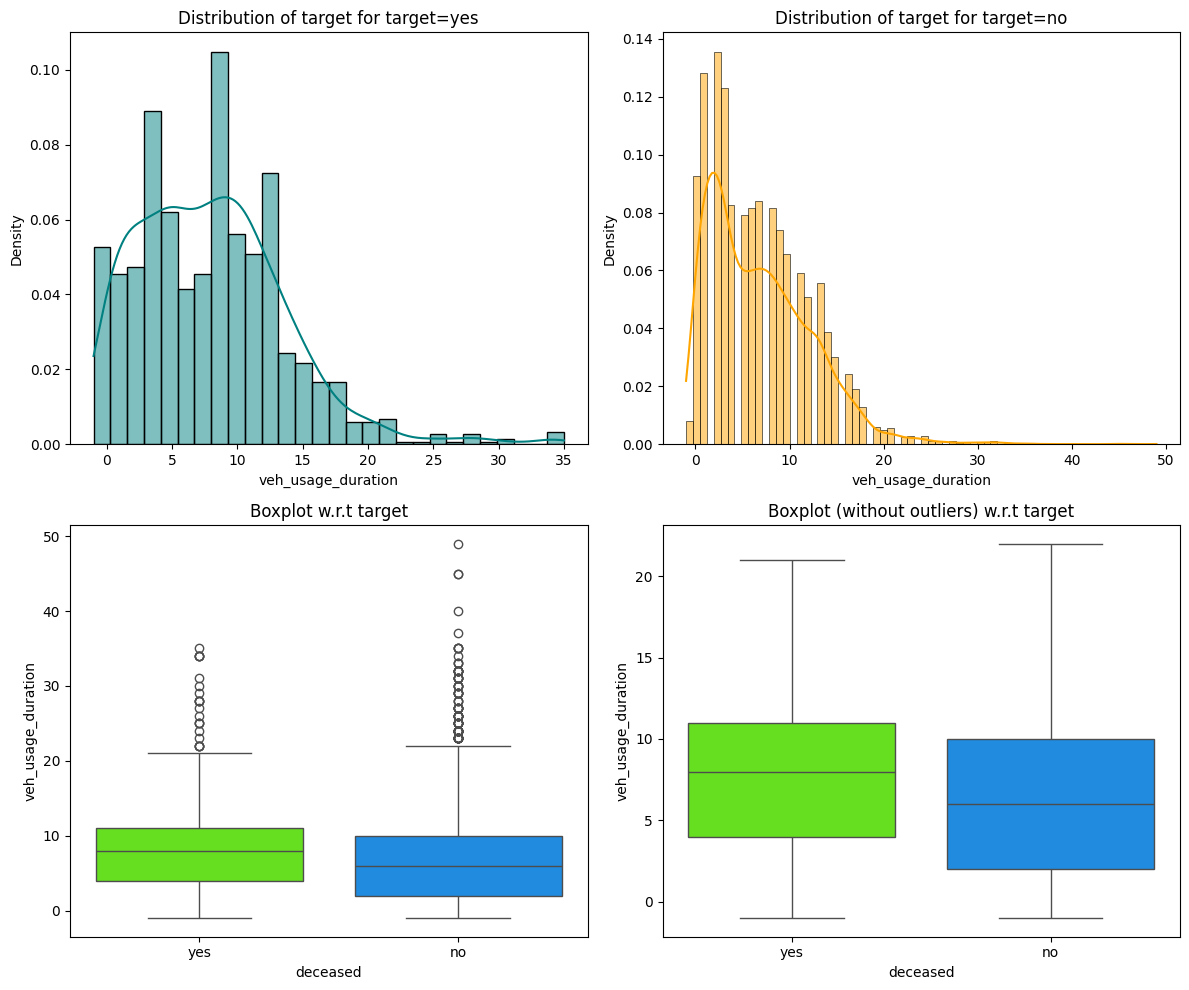

In [ ]:
distribution_plot_wrt_target(data, "veh_usage_duration", "deceased")  ## Complete the code to get distribution_plot_wrt_target for veh_usage_duration and deceased

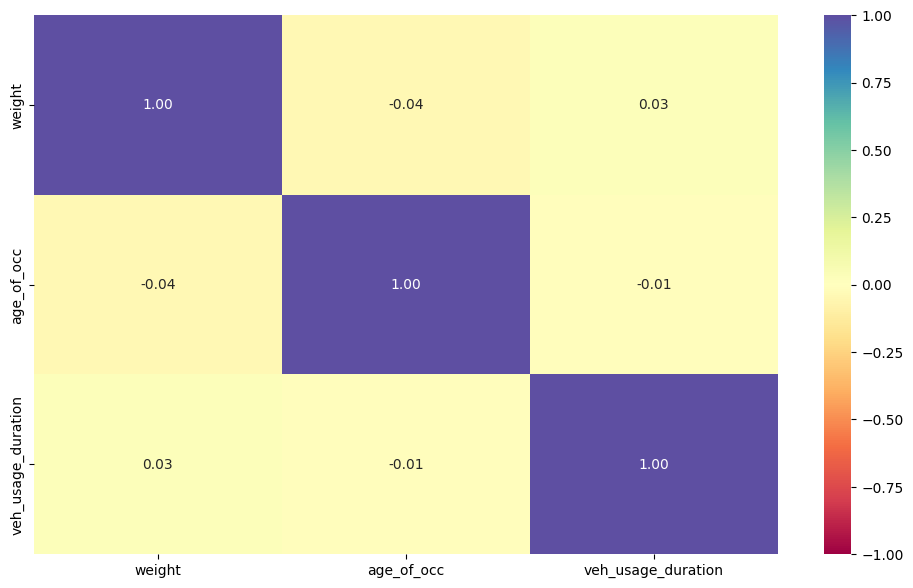

In [ ]:
cols_list = ["weight", "age_of_occ", "veh_usage_duration"]

plt.figure(figsize=(12, 7))
sns.heatmap(
    data[cols_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()

# **Data Preprocessing**

### Outlier Check

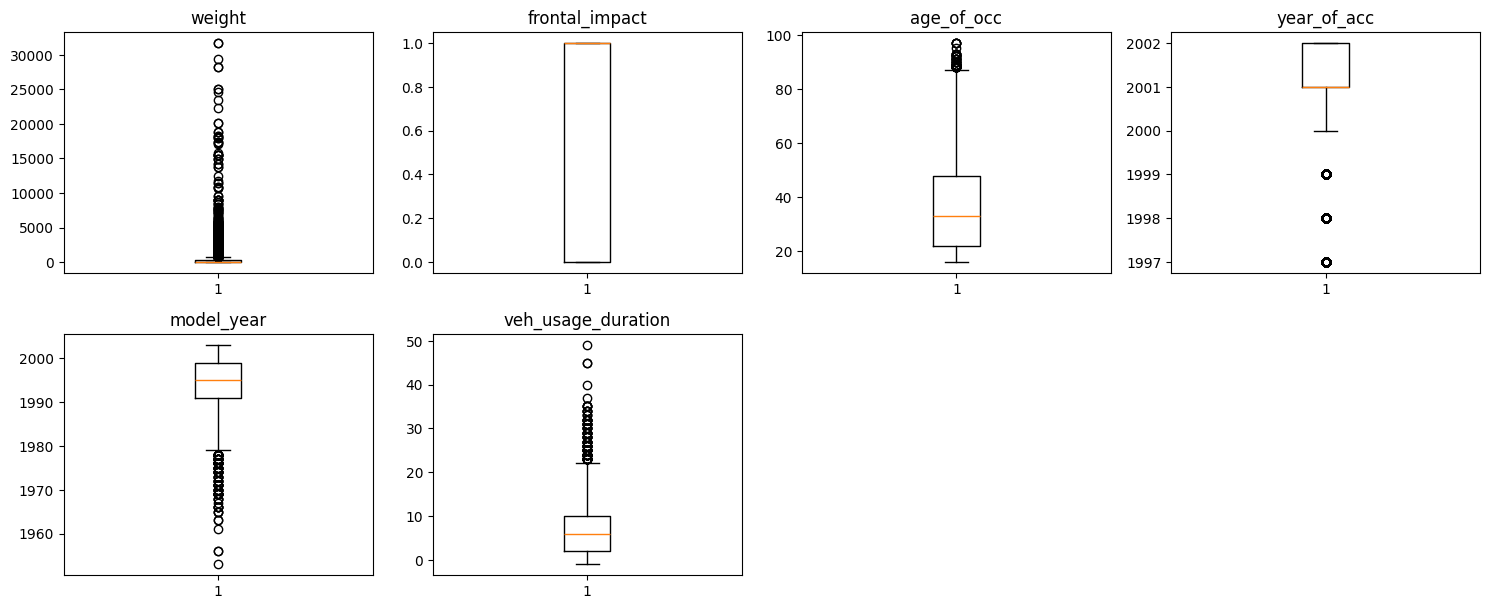

In [ ]:
# outlier detection using boxplot
numeric_columns = data.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(data[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

### Data Preparation for modeling

**Let's drop the unnecessary columns first before we proceed forward**.

In [ ]:
data.drop(['caseid', 'year_of_acc', 'model_year'], axis=1, inplace=True)
  ## Complete the code to drop the unnecessary columns (caseid, year_of_acc, and model_year)

In [ ]:
data.head()

,speed_range,weight,seatbelt,frontal_impact,sex,age_of_occ,airbag,occ_role,deceased,veh_usage_duration
0,55+ km/h,27.07800,none,1,m,32,unavail,driver,yes,10
1,25-39 km/h,89.62700,belted,0,f,54,nodeploy,driver,yes,3
2,55+ km/h,27.07800,belted,1,m,67,unavail,driver,yes,5
3,55+ km/h,27.07800,belted,1,f,64,unavail,pass,yes,5
4,55+ km/h,13.37400,none,1,m,23,unavail,driver,yes,11


In [ ]:
data["deceased"].replace({"no":0, "yes":1},inplace=True)

In [ ]:
X = data.drop(["deceased"], axis=1)
Y = data["deceased"]

X = pd.get_dummies(X, drop_first=True)

X = X.astype(float)

# Splitting data in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.3, random_state=42
)## Complete the code to split the data in 70:30 ratio

In [ ]:
y_train.reset_index(inplace = True, drop = True)

In [ ]:
print("Shape of Training set : ", X_train.shape)
print("Shape of test set : ", X_test.shape)
print("Shape of Training set : ", y_train.shape)
print("Shape of test set : ", y_test.shape)
print("Percentage of classes in training set:")
print(y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(y_test.value_counts(normalize=True))

Shape of Training set :  (7851, 13)
Shape of test set :  (3366, 13)
Shape of Training set :  (7851,)
Shape of test set :  (3366,)
Percentage of classes in training set:
deceased
0   0.89530
1   0.10470
Name: proportion, dtype: float64
Percentage of classes in test set:
deceased
0   0.89364
1   0.10636
Name: proportion, dtype: float64


###Scaling the Data

In [ ]:
sc = StandardScaler()

X_train_scaled = pd.DataFrame(sc.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(sc.transform(X_test), columns=X_test.columns)

# **Model Building**

## Model evaluation criterion

*  

First, let's create functions to calculate different metrics and confusion matrix so that we don't have to use the same code repeatedly for each model.
* The model_performance_classification_sklearn function will be used to check the model performance of models.
* The confusion_matrix_sklearn function will be used to plot the confusion matrix.

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn
def model_performance_classification(model, predictors, target, threshold = 0.5):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    prob_pred = model.predict(predictors)
    class_pred = [1 if i >= threshold else 0 for i in prob_pred]

    acc = accuracy_score(target, class_pred)  # to compute Accuracy
    recall = recall_score(target, class_pred)  # to compute Recall
    precision = precision_score(target, class_pred)  # to compute Precision
    f1 = f1_score(target, class_pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

In [ ]:
def plot_confusion_matrix(model, predictors, target, threshold = 0.5):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    prob_pred = model.predict(predictors)
    class_pred = [1 if i >= threshold else 0 for i in prob_pred]
    cm = confusion_matrix(target, class_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

## Logistic Regression (with Statsmodel)

In [ ]:
# Adding constant to data for Logistic Regression
X_train_with_intercept = SM.add_constant(X_train_scaled)
X_test_with_intercept = SM.add_constant(X_test_scaled)

In [ ]:
X_train_with_intercept.head()

,const,weight,frontal_impact,age_of_occ,veh_usage_duration,speed_range_10-24 km/h,speed_range_25-39 km/h,speed_range_40-54 km/h,speed_range_55+ km/h,seatbelt_none,sex_m,airbag_nodeploy,airbag_unavail,occ_role_pass
0,1.00000,-0.15444,-1.34236,-0.84838,1.11010,-0.97348,1.54925,-0.36813,-0.28453,-0.65420,0.91931,-0.56740,1.31055,-0.52927
1,1.00000,0.47399,-1.34236,-1.12278,0.56322,1.02725,-0.64547,-0.36813,-0.28453,-0.65420,0.91931,-0.56740,1.31055,-0.52927
2,1.00000,-0.30476,0.74496,-1.12278,-0.89511,-0.97348,1.54925,-0.36813,-0.28453,-0.65420,0.91931,-0.56740,-0.76304,-0.52927
3,1.00000,0.27321,0.74496,-1.17766,0.56322,1.02725,-0.64547,-0.36813,-0.28453,-0.65420,0.91931,-0.56740,-0.76304,-0.52927
4,1.00000,0.19543,0.74496,-0.13494,2.02155,-0.97348,1.54925,-0.36813,-0.28453,1.52859,-1.08778,-0.56740,1.31055,-0.52927


In [ ]:
LogisticReg = SM.Logit(y_train, X_train_with_intercept).fit()
print(LogisticReg.summary())

Optimization terminated successfully.
         Current function value: 0.207203
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:               deceased   No. Observations:                 7851
Model:                          Logit   Df Residuals:                     7837
Method:                           MLE   Df Model:                           13
Date:                Fri, 19 Sep 2025   Pseudo R-squ.:                  0.3820
Time:                        00:23:41   Log-Likelihood:                -1626.8
converged:                       True   LL-Null:                       -2632.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -4.6071      0.194    -23.731      0.000      -4.988     

### Checking Logistic Regression model performance on training set

In [ ]:
y_pred = LogisticReg.predict(X_train_with_intercept)
y_pred.head()

,0
0,0.04329
1,0.00032
2,0.01684
3,0.00007
4,0.00443


In [ ]:
logistic_reg_perf_train = model_performance_classification(
    LogisticReg, X_train_with_intercept, y_train
)
logistic_reg_perf_train

,Accuracy,Recall,Precision,F1
0,0.91160,0.35645,0.63974,0.45781


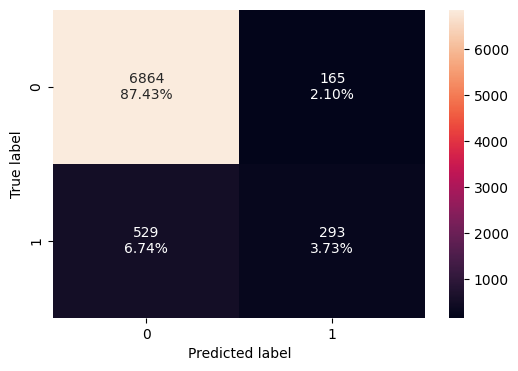

In [ ]:
plot_confusion_matrix(LogisticReg, X_train_with_intercept, y_train)

### Checking Logistic Regression model performance on test set

In [ ]:
logistic_reg_perf_test = model_performance_classification(
    LogisticReg, X_test_with_intercept, y_test
)
logistic_reg_perf_test

,Accuracy,Recall,Precision,F1
0,0.91503,0.38268,0.67822,0.48929


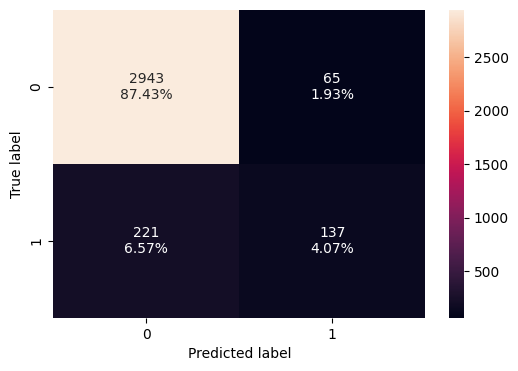

In [ ]:
plot_confusion_matrix(LogisticReg, X_test_with_intercept, y_test)

## Decision Tree Classifier

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

### Checking Decision Tree Classifier performance on training set

In [ ]:
decision_tree_perf_train = model_performance_classification(dt_model, X_train, y_train)
decision_tree_perf_train

,Accuracy,Recall,Precision,F1
0,1.00000,1.00000,1.00000,1.00000


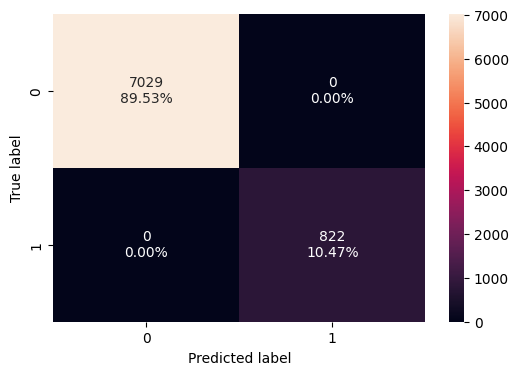

In [ ]:
plot_confusion_matrix(dt_model, X_train, y_train)  ## Complete the code to plot the confusion matrix for training set

### Checking Decision Tree Classifier performance on test set

In [ ]:
decision_tree_perf_test = model_performance_classification(dt_model, X_test, y_test)  ## Complete the code to get the model performance on test set
decision_tree_perf_test

,Accuracy,Recall,Precision,F1
0,0.88770,0.42458,0.46914,0.44575


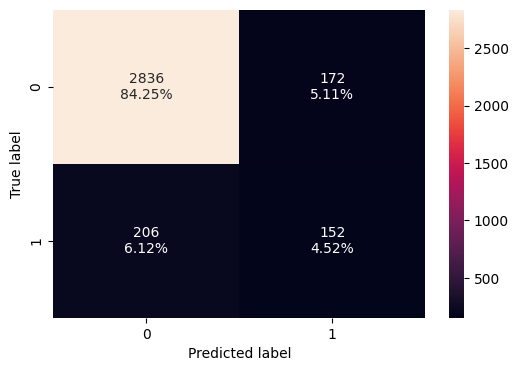

In [ ]:
plot_confusion_matrix(dt_model, X_test, y_test)  ## Complete the code to plot the confusion matrix for test set

# **Model Performance Improvement**

## Logistic Regression (deal with high p-value variables and determine optimal threshold using ROC curve)

### Dealing with high p-value variables

In [ ]:
# initial list of columns
predictors = X_train_with_intercept.copy()
cols = predictors.columns.tolist()

# setting an initial max p-value
max_p_value = 1

while len(cols) > 0:
    # defining the train set
    x_train_aux = predictors[cols]

    # fitting the model
    model = SM.Logit(y_train, x_train_aux).fit()

    # getting the p-values and the maximum p-value
    p_values = model.pvalues
    max_p_value = max(p_values)

    # name of the variable with maximum p-value
    feature_with_p_max = p_values.idxmax()

    if max_p_value > 0.05:
        cols.remove(feature_with_p_max)
        print(f"Dropping column {feature_with_p_max} with p-value: {max_p_value}")
    else:
        break

selected_features = cols
print(selected_features)

Optimization terminated successfully.
         Current function value: 0.207203
         Iterations 11
Dropping column speed_range_10-24 km/h with p-value: 0.781931414978237
Optimization terminated successfully.
         Current function value: 0.207208
         Iterations 11
Dropping column sex_m with p-value: 0.3947051170625223
Optimization terminated successfully.
         Current function value: 0.207255
         Iterations 11
Dropping column airbag_nodeploy with p-value: 0.27721208781847273
Optimization terminated successfully.
         Current function value: 0.207330
         Iterations 11
Dropping column occ_role_pass with p-value: 0.17757127901936154
Optimization terminated successfully.
         Current function value: 0.207445
         Iterations 11
['const', 'weight', 'frontal_impact', 'age_of_occ', 'veh_usage_duration', 'speed_range_25-39 km/h', 'speed_range_40-54 km/h', 'speed_range_55+ km/h', 'seatbelt_none', 'airbag_unavail']


In [ ]:
X_train_significant = X_train_with_intercept[selected_features]
X_test_significant = X_test_with_intercept[selected_features]  ## Complete the code to get the test set with significant features
X_train_significant.head(10)

,const,weight,frontal_impact,age_of_occ,veh_usage_duration,speed_range_25-39 km/h,speed_range_40-54 km/h,speed_range_55+ km/h,seatbelt_none,airbag_unavail
0,1.00000,-0.15444,-1.34236,-0.84838,1.11010,1.54925,-0.36813,-0.28453,-0.65420,1.31055
1,1.00000,0.47399,-1.34236,-1.12278,0.56322,-0.64547,-0.36813,-0.28453,-0.65420,1.31055
2,1.00000,-0.30476,0.74496,-1.12278,-0.89511,1.54925,-0.36813,-0.28453,-0.65420,-0.76304
3,1.00000,0.27321,0.74496,-1.17766,0.56322,-0.64547,-0.36813,-0.28453,-0.65420,-0.76304
4,1.00000,0.19543,0.74496,-0.13494,2.02155,1.54925,-0.36813,-0.28453,1.52859,1.31055
5,1.00000,-0.12072,0.74496,-0.57398,-1.07740,1.54925,-0.36813,-0.28453,-0.65420,-0.76304
6,1.00000,-0.29066,0.74496,2.99320,-0.34824,1.54925,-0.36813,-0.28453,-0.65420,-0.76304
7,1.00000,2.13117,0.74496,-0.62886,-1.07740,-0.64547,-0.36813,-0.28453,-0.65420,-0.76304
8,1.00000,-0.27989,0.74496,-0.40934,0.19864,-0.64547,-0.36813,3.51455,-0.65420,1.31055
9,1.00000,-0.17273,-1.34236,-0.73862,-0.71282,-0.64547,2.71641,-0.28453,-0.65420,-0.76304


### Training the Logistic Regression model again with only the significant features

In [ ]:
LogisticReg_2 = SM.Logit(y_train, X_train_significant).fit()  ## Complete the code to train the Logistic Regression model with significant features
print(LogisticReg_2.summary())

Optimization terminated successfully.
         Current function value: 0.207445
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:               deceased   No. Observations:                 7851
Model:                          Logit   Df Residuals:                     7841
Method:                           MLE   Df Model:                            9
Date:                Fri, 19 Sep 2025   Pseudo R-squ.:                  0.3813
Time:                        01:33:05   Log-Likelihood:                -1628.7
converged:                       True   LL-Null:                       -2632.4
Covariance Type:            nonrobust   LLR p-value:                     0.000
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     -4.6124      0.195    -23.712      0.000      -4.994     

### Determining optimal threshold using ROC Curve

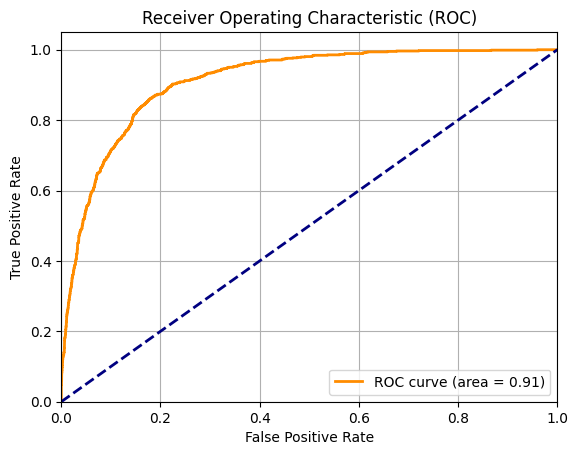

In [ ]:
y_pred = LogisticReg_2.predict(X_train_significant)
fpr, tpr, thresholds = roc_curve(y_train, y_pred)

# Plot ROC curve
roc_auc = roc_auc_score(y_train, y_pred)  ## Complete the code to get the ROC-AUC score
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.grid()
plt.show()

In [ ]:
# Find the optimal threshold
optimal_idx = np.argmax(tpr - fpr)
optimal_threshold_logit = round(thresholds[optimal_idx], 3)
print("\nOptimal Threshold: ", optimal_threshold_logit)


Optimal Threshold:  0.111


### Checking new Logistic Regression model performance on training set

In [ ]:
logistic_reg_new_perf_train = model_performance_classification(
    LogisticReg_2, X_train_significant, y_train, optimal_threshold_logit
)
logistic_reg_new_perf_train

,Accuracy,Recall,Precision,F1
0,0.82525,0.86131,0.36012,0.50789


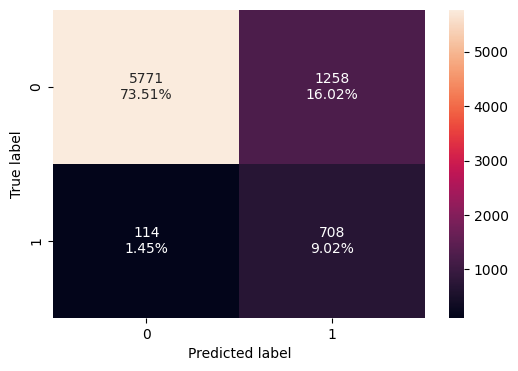

In [ ]:
plot_confusion_matrix(LogisticReg_2, X_train_significant, y_train, optimal_threshold_logit)

### Checking tuned Logistic Regression model performance on test set

In [ ]:
logistic_reg_new_perf_test = model_performance_classification(
    LogisticReg_2, X_test_significant, y_test, optimal_threshold_logit
)

logistic_reg_new_perf_test

,Accuracy,Recall,Precision,F1
0,0.82620,0.85475,0.36472,0.51128


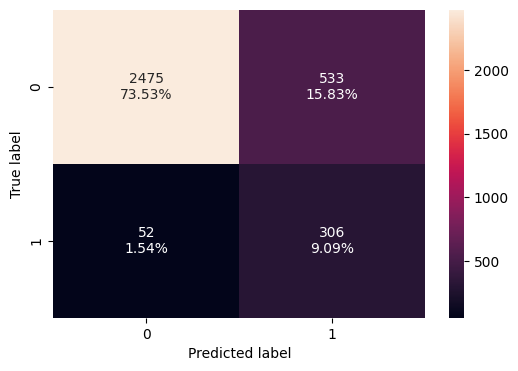

In [ ]:
plot_confusion_matrix(LogisticReg_2, X_test_significant, y_test, optimal_threshold_logit)

## Decision Tree Classifier (pre-pruning)

### Pre-pruning the tree

In [ ]:
# Choose the type of classifier.
dt_model_tuned = DecisionTreeClassifier(random_state=42)

# Grid of parameters to choose from
parameters = {
    "max_depth": np.arange(5, 13, 2),                          ## Max Depth of the decision tree
    "max_leaf_nodes": [10, 20, 40, 50, 75, 100],               ## Maximum number of leaf nodes
    "min_samples_split": [2, 5, 7, 10, 20, 30],                ## Minimum number of samples required to split an internal node
    "class_weight": ['balanced', None]                         ## whether or not to used balanced weights for impurity computations
}

# Run the grid search
grid_obj = GridSearchCV(dt_model_tuned, parameters, scoring='recall', cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
dt_model_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
dt_model_tuned.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=np.int64(5),
                       max_leaf_nodes=10, random_state=42)

### Checking tuned Decision Tree Classifier performance on training set

In [ ]:
decision_tree_tuned_perf_train = model_performance_classification(dt_model_tuned, X_train, y_train)  ## Complete the code to get model performance on training data
decision_tree_tuned_perf_train

,Accuracy,Recall,Precision,F1
0,0.77608,0.86983,0.30220,0.44856


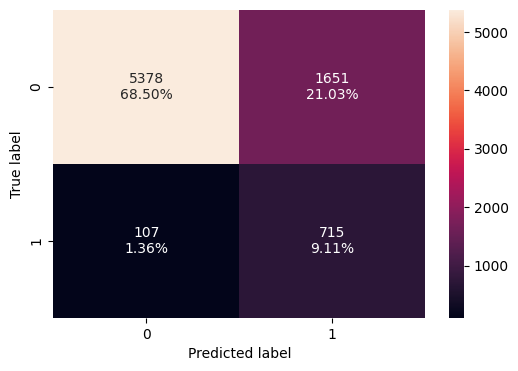

In [ ]:
plot_confusion_matrix(dt_model_tuned, X_train, y_train)  ## Complete the code to create confusion matrix for training data

### Checking tuned Decision Tree Classifier performance on test set

In [ ]:
decision_tree_tuned_perf_test = model_performance_classification(dt_model_tuned, X_test, y_test)  ## Complete the code to get model performance on test data
decision_tree_tuned_perf_test

,Accuracy,Recall,Precision,F1
0,0.77718,0.85475,0.30478,0.44934


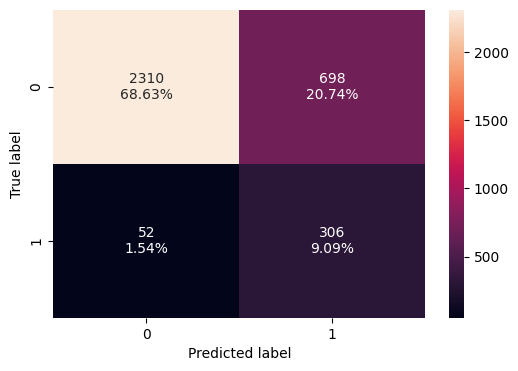

In [ ]:
plot_confusion_matrix(dt_model_tuned, X_test, y_test)  ## Complete the code to create confusion matrix for test data

### Visualizing the Decision Tree

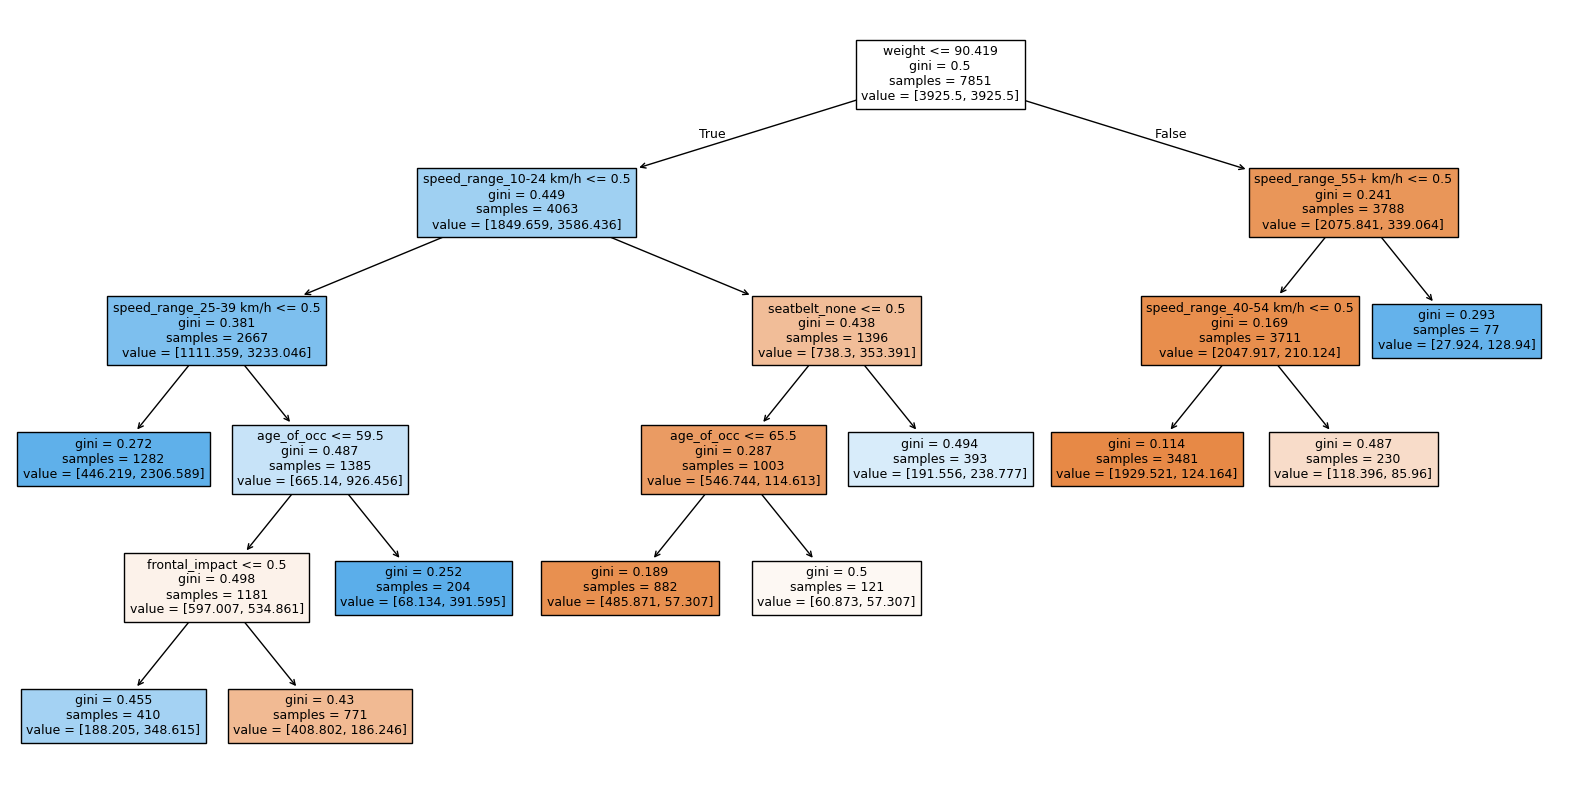

In [ ]:
plt.figure(figsize=(20, 10))
out = tree.plot_tree(
    dt_model_tuned,
    feature_names=X_train.columns.tolist(),
    filled=True,
    fontsize=9,
    node_ids=False,
    class_names=None,
)
# below code will add arrows to the decision tree split if they are missing
for o in out:
    arrow = o.arrow_patch
    if arrow is not None:
        arrow.set_edgecolor("black")
        arrow.set_linewidth(1)
plt.show()

### Analyzing Feature Importance for tuned Decision Tree Classifier

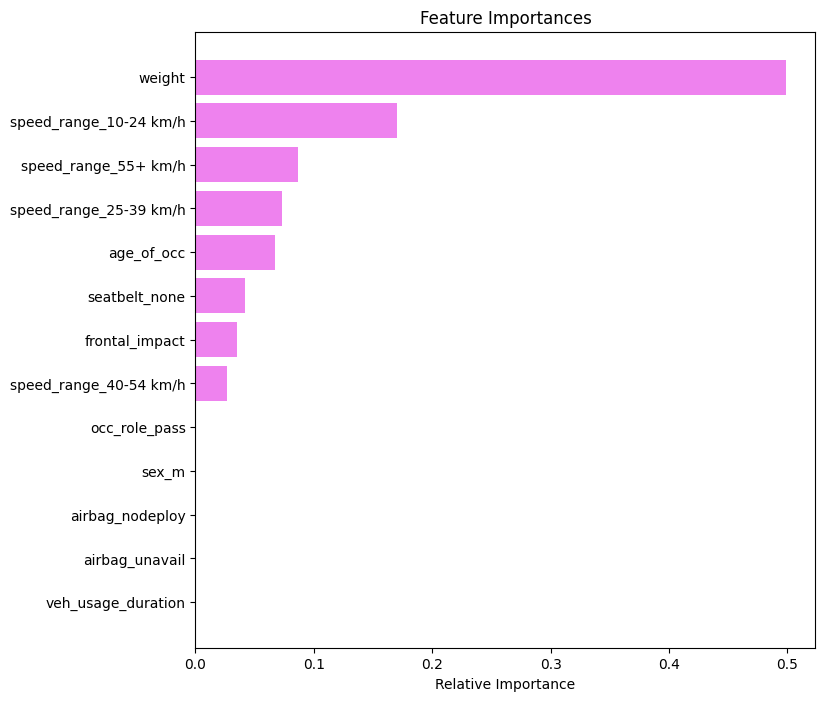

In [ ]:
# Uncomment and run to check feature importance for Tuned Decision Tree model


# importance of features in the tree building

feature_names = X_train.columns.tolist()
importances = dt_model_tuned.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 8))
plt.title("Feature Importances")
plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Relative Importance")
plt.show()

#### Observations from decision tree

*  


# **Model Performance Comparison and Final Model Selection**

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [
        logistic_reg_perf_train.T,
        logistic_reg_new_perf_train.T,
        decision_tree_perf_train.T,
        decision_tree_tuned_perf_train.T
            ],
    axis=1,
)
models_train_comp_df.columns = [
    "Logistic Regression Base",
    "Logistic Regression (Optimal threshold)",
    "Decision Tree Base",
    "Decision Tree Tuned"
]
print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Logistic Regression Base,Logistic Regression (Optimal threshold),Decision Tree Base,Decision Tree Tuned
Accuracy,0.91160,0.82525,1.00000,0.77608
Recall,0.35645,0.86131,1.00000,0.86983
Precision,0.63974,0.36012,1.00000,0.30220
F1,0.45781,0.50789,1.00000,0.44856


In [ ]:
# testing performance comparison

models_test_comp_df = pd.concat(
    [
        logistic_reg_perf_test.T,
        logistic_reg_new_perf_test.T,
        decision_tree_perf_test.T,
        decision_tree_tuned_perf_test.T
    ],
    axis=1,
)
models_test_comp_df.columns = [
    "Logistic Regression Base",
    "Logistic Regression (Optimal threshold)",
    "Decision Tree Base",
    "Decision Tree Tuned"
]
print("Test set performance comparison:")
models_test_comp_df

Test set performance comparison:


,Logistic Regression Base,Logistic Regression (Optimal threshold),Decision Tree Base,Decision Tree Tuned
Accuracy,0.91503,0.82620,0.88770,0.77718
Recall,0.38268,0.85475,0.42458,0.85475
Precision,0.67822,0.36472,0.46914,0.30478
F1,0.48929,0.51128,0.44575,0.44934


**Observations**
*  

# **Actionable Insights and Recommendations**

### Actionable Insights


*  



### Business Recommendations


*  